# Validation of 3D outputs

This notebooks uses the [modelskill](https://dhi.github.io/modelskill/) package for validating the 3D model output data.

Note, that this notebook has been prepared using an alpha-release of modelskill (1.4.0a3). 3D validation has not been implemented in prior versions, so at least 1.4.0a3 is required, but the code might need slight modification for future releases.

In [1]:
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
mr_fldr = "../output_sample/"
# mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "3D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

# Temperature and salinity

Load the in-situ measurement data of temperature and salinity

In [3]:
stations = pd.read_csv("../observations/stations_TS.csv",sep=";", usecols=["Station", "lon", "lat"])
stations

,Station,lon,lat
0,FRB9070,12.638,55.924
1,KBH431,12.750,55.867
2,KBK1728,12.714,55.537


In [ ]:
def validate_ts_station(station_name, xpos, ypos, z_ts=-24):
    quants = ['T', 'S']
    names = {'T': 'Temperature', 'S': 'Salinity'}
    units = {'T': '°C', 'S': 'PSU'}

    for q in quants:
        obs_data = pd.read_csv(f"{obs_fldr}{station_name}_{q}_All.csv", index_col=0, parse_dates=True)
        obs_data = obs_data.sort_index()
        vo = ms.VerticalObservation(
            obs_data,
            item=names[q].lower(),
            z_item="z",
            x=xpos,
            y=ypos,
            quantity=ms.Quantity(names[q], units[q]),
        )
        mr = ms.DfsuModelResult(f"{mr_fldr}{mr_fn}", item=names[q], name="MIKE3")
        ax = ms.plotting.spatial_overview(vo, mr)
        try:
            cmp = ms.match(vo, mr)
            cmp.skill()

            fig, ax = plt.subplots(2, 3, figsize=(18, 12))
            _ = cmp.plot(ax=ax[0,0])
            _ = cmp.plot.hist(ax=ax[0,1])
            _ = cmp.plot.kde(ax=ax[0,2])
            _ = cmp.plot.box(ax=ax[1,0])
            _ = cmp.plot.qq(ax=ax[1,1])
            _ = cmp.sel(z=z_ts).plot.timeseries(ax=ax[1,2])
            plt.tight_layout()
            if save_png: plt.savefig(f"../figures/{station_name}_{q}_comparison.png", dpi=300, bbox_inches='tight')
            plt.show()

            sk = cmp.vertical.skill(bins=[-25, -20, -15, -10, -5, 0])
            print(sk.to_dataframe())

            ax = cmp.vertical.plot.hovmoller(figsize=(16, 5), obs_marker_size=100)
            plt.tight_layout()
            if save_png: plt.savefig(f"../figures/{station_name}_{q}_hovmoller.png", dpi=300, bbox_inches='tight')
            plt.show()
        except Exception as e:
            print(f"Error processing {station_name} for {q}: {e}")

## FRB station
Load the data belonging to the FRB station and use modelskill to compare to the model data

In [4]:
i = 0
station_name = stations.loc[i, "Station"]
xpos = stations.loc[i, 'lon']
ypos = stations.loc[i, 'lat']

In [ ]:
validate_ts_station(station_name, xpos, ypos, z_ts=-24)

The model captures temperature very well, but is more challenged on modelling the salinity, which is generally underpredicted. This is information that could be used to calibrate the model further, but we remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational purposes. 

## KBH station

In [7]:
i = 1
station_name = stations.loc[i, "Station"]
xpos = stations.loc[i, 'lon']
ypos = stations.loc[i, 'lat']

In [ ]:
validate_ts_station(station_name, xpos, ypos, z_ts=-24)

The model captures temperature very well, but is more challenged on modelling the salinity, which is generally underpredicted. This is information that could be used to calibrate the model further, but we remind the user that the current model setup has not been calibrated to full capacity, and should therefore only be used for educational purposes. 

## KBH station 2

In [ ]:
i = 2
station_name = stations.loc[i, "Station"]
xpos = stations.loc[i, 'lon']
ypos = stations.loc[i, 'lat']

In [ ]:
validate_ts_station(station_name, xpos, ypos, z_ts=-10)

The model captures temperature very well, and compared to the other two in-situ stations, the salinity here is captured relatively well. 

# Currents

Load data for validating the current velocity predictions.

In [ ]:
stations = pd.read_csv("../observations/stations_uv.csv", usecols=["Station", "Longitude", "Latitude"])
stations

,Station,Longitude,Latitude
0,Flinten7,12.8445,55.5894
1,Flinten16,12.8095,55.5610


In [ ]:
ts_plot = slice("2025-01-01", "2025-04-30")

## Flinten 7

In [ ]:
i = 0
station_name = stations.loc[i, "Station"]
xpos = stations.loc[i, 'Longitude']
ypos = stations.loc[i, 'Latitude']

KeyboardInterrupt: 

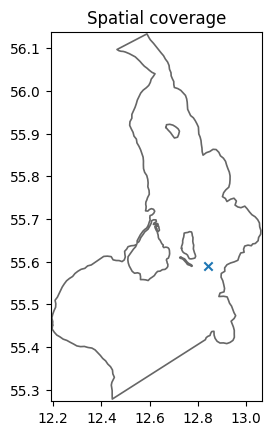

In [ ]:
quants = ['u', 'v']

names = {
    'u': 'U velocity',
    'v': 'V velocity'
}
units = {
    'u': 'm/s',
    'v': 'm/s'
}

for q in quants:
    obs_data = pd.read_csv(f"{obs_fldr}{station_name}_u_v.csv", index_col=0,parse_dates=True)
    obs_data = obs_data.sort_index()
    vo = ms.VerticalObservation(
        obs_data,
        item=q,
        z_item="z",
        x=xpos,
        y=ypos,
        quantity=ms.Quantity(names[q], units[q]),
    )
    mr = ms.DfsuModelResult(f"{mr_fldr}{mr_fn}", item= names[q], name="MIKE3")
    ax = ms.plotting.spatial_overview(vo, mr)
    cmp = ms.match(vo, mr)
    cmp.skill()

    fig, ax = plt.subplots(2,3, figsize=(18,12))
    _ = cmp.plot(ax=ax[0,0])
    _ = cmp.plot.hist(ax=ax[0,1])
    _ = cmp.plot.kde(ax=ax[0,2])
    _ = cmp.plot.box(ax=ax[1,0])
    _ = cmp.plot.qq(ax=ax[1,1])
    _ = cmp.sel(z=-4,time=ts_plot).plot.timeseries(ax=ax[1,2])
    plt.tight_layout()
    if save_png: plt.savefig(f"../figures/{station_name}_{q}_comparison.png", dpi=300,bbox_inches='tight')
    plt.show()

    # Custom bins
    sk = cmp.vertical.skill(bins=[-6, -4, -2, 0])
    print(sk.to_dataframe())




## Flinten 16

In [ ]:
i = 1
station_name = stations.loc[i, "Station"]
xpos = stations.loc[i, 'Longitude']
ypos = stations.loc[i, 'Latitude']

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


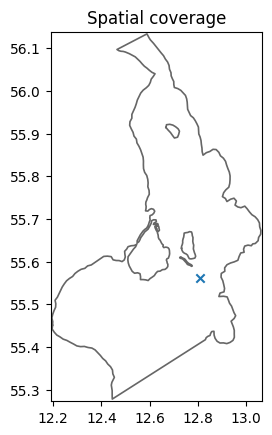

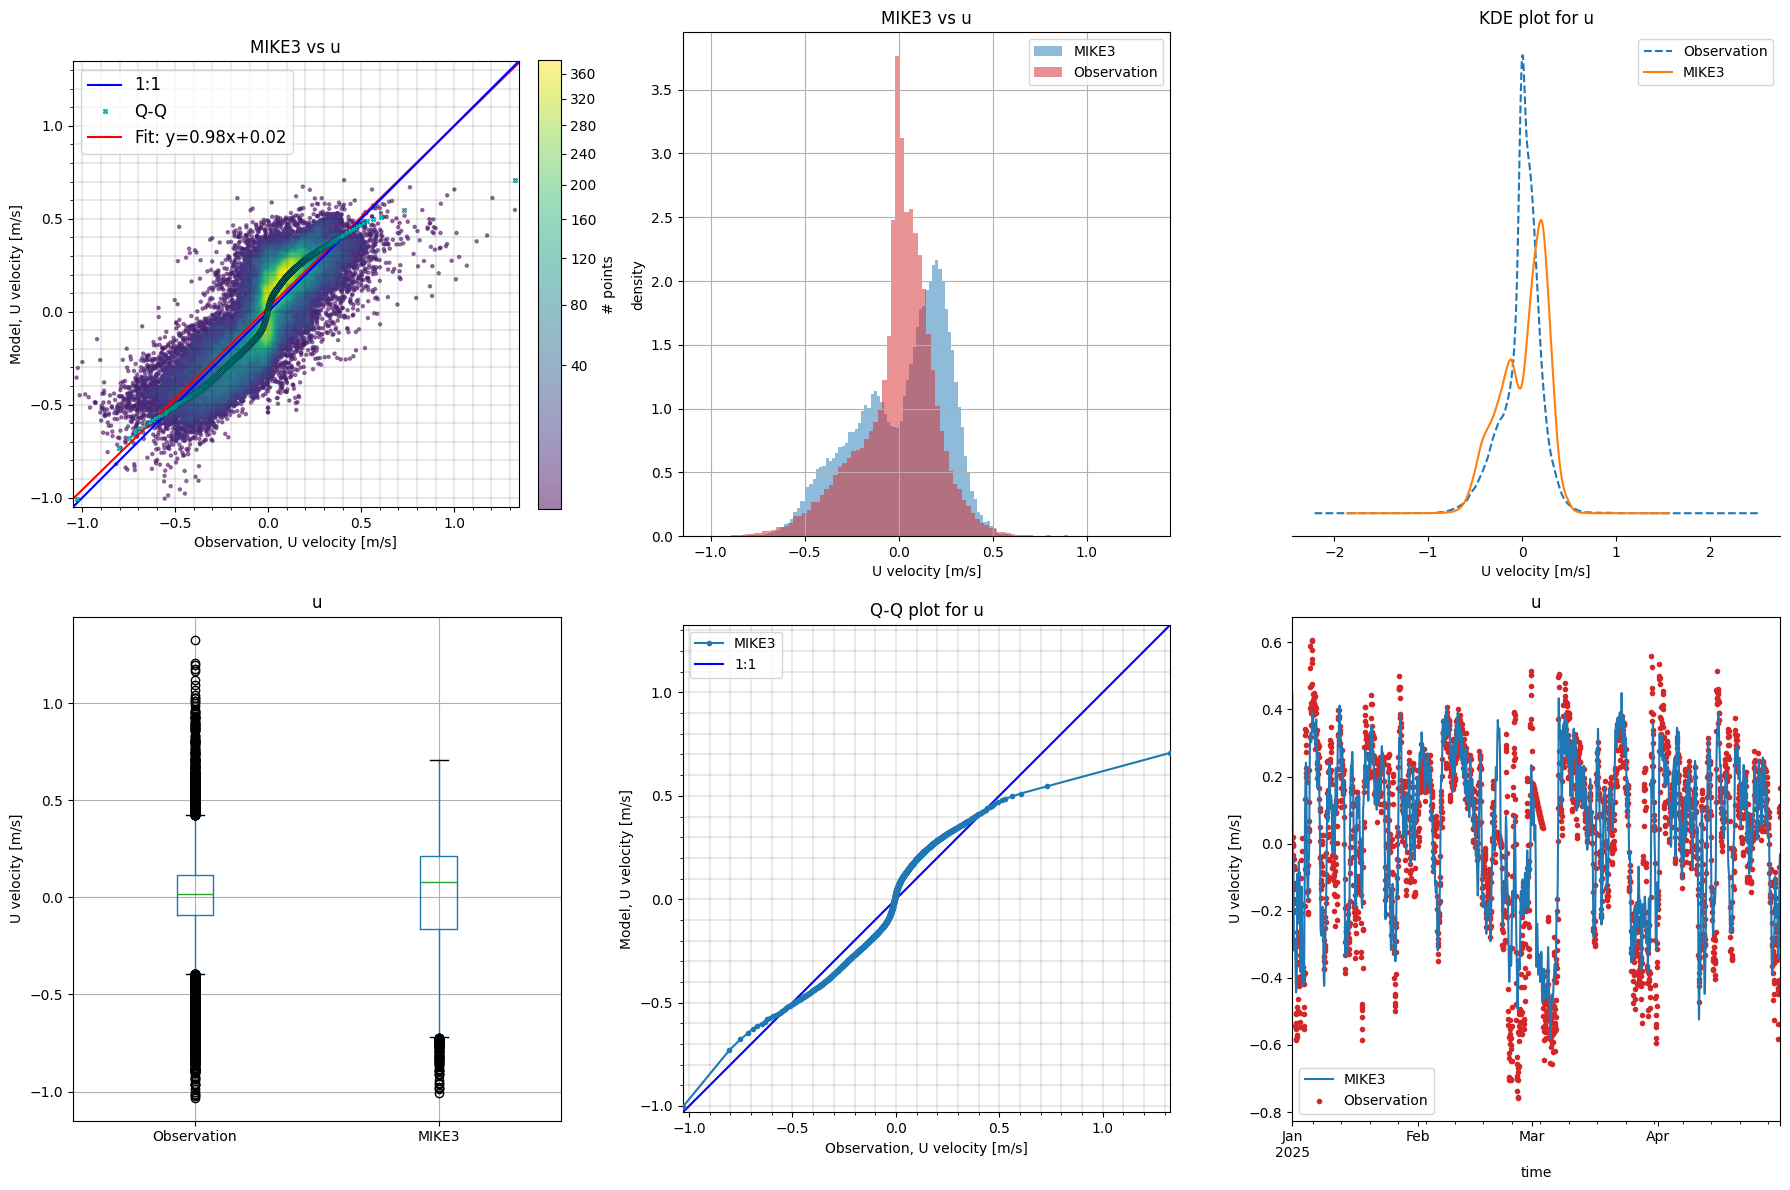

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.015587  0.116000  0.114948  0.089763  0.887576  0.591809   
(-4, -2]  0.025233  0.160466  0.158470  0.129508  0.813273  0.910317   
(-2, 0]   0.143787  0.348695  0.317669  0.302125  0.217266  1.359046   

                r2      n  
z                          
(-6, -4]  0.762461  25913  
(-4, -2]  0.516433  26013  
(-2, 0]  -0.341162   1247  


c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(


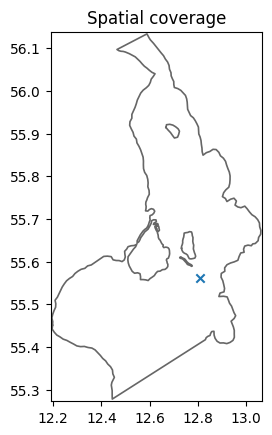

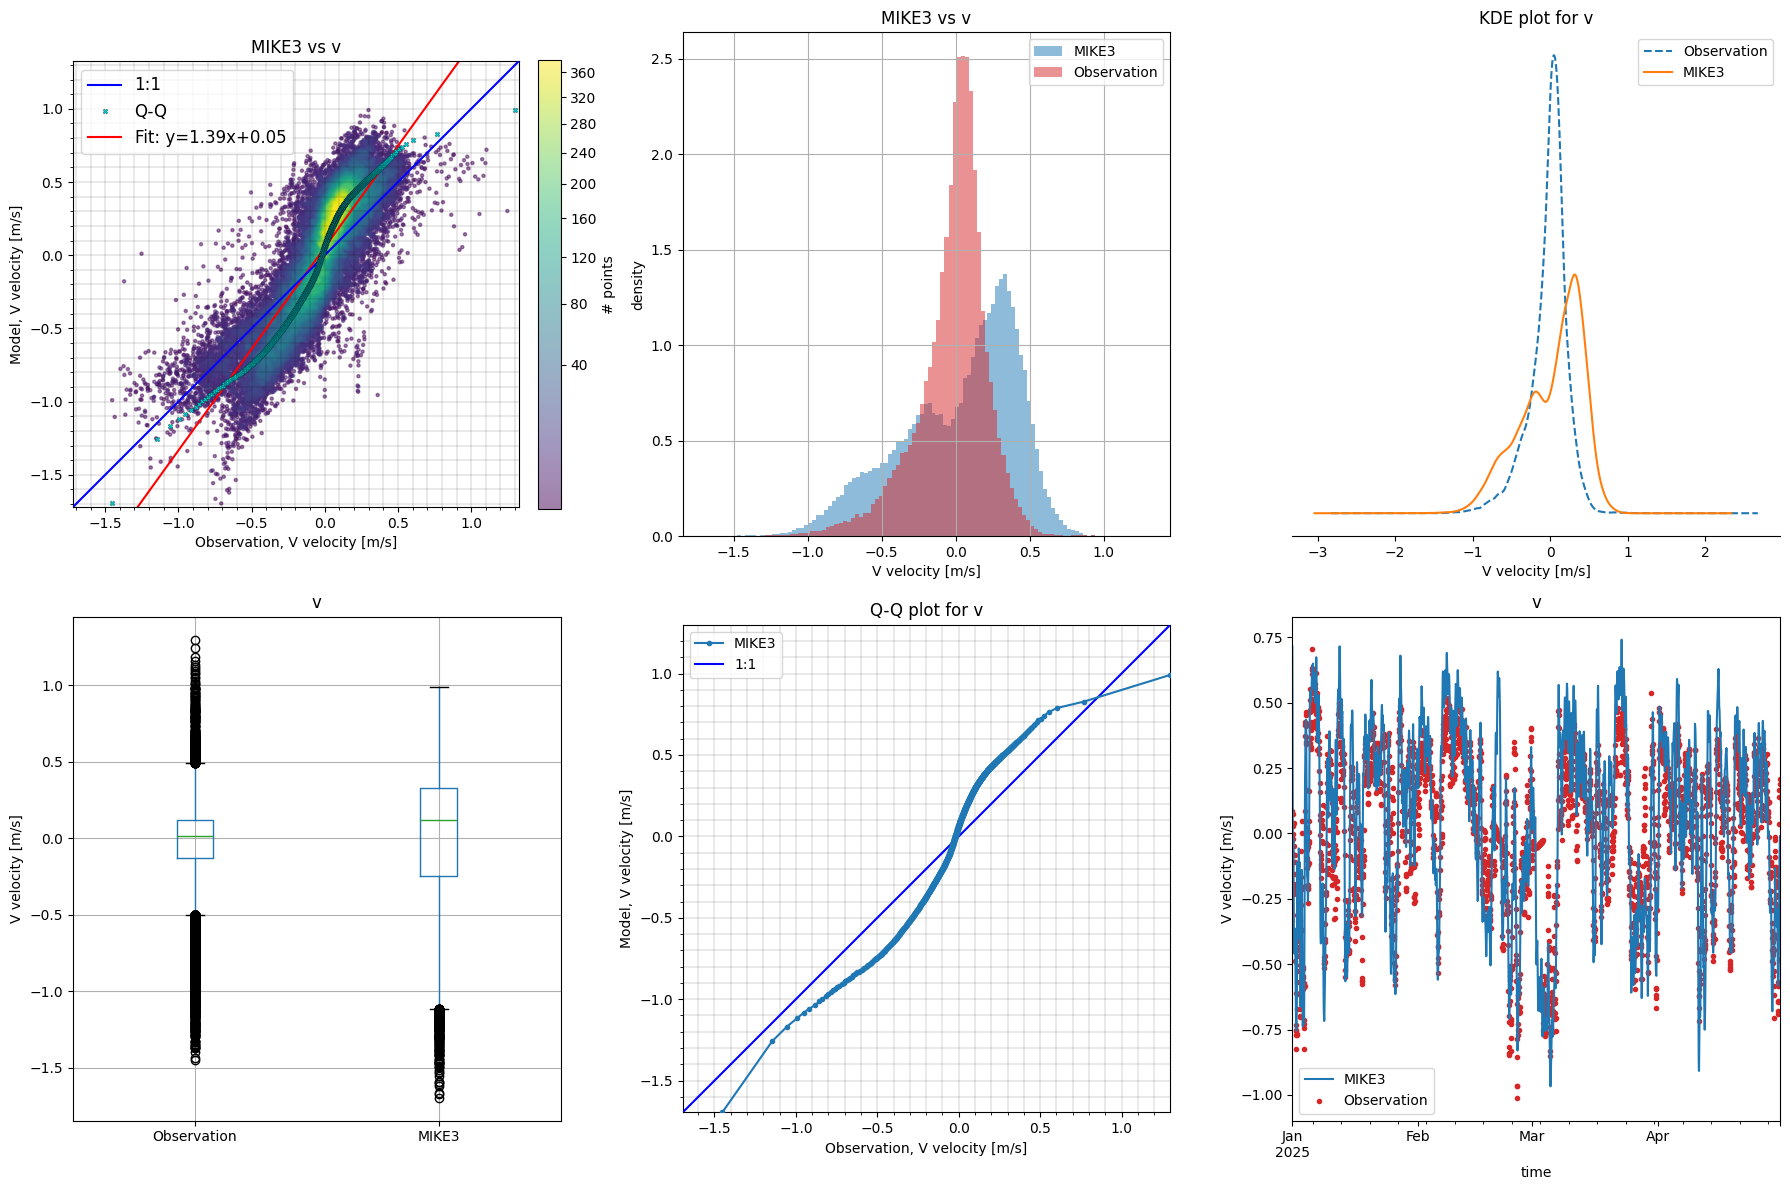

              bias      rmse     urmse       mae        cc        si  \
z                                                                      
(-6, -4]  0.040918  0.211402  0.207405  0.172270  0.878544  1.046515   
(-4, -2]  0.050710  0.254497  0.249394  0.213001  0.834388  1.285170   
(-2, 0]   0.346339  0.435299  0.263694  0.388407  0.596099  1.162710   

                r2      n  
z                          
(-6, -4]  0.349064  25913  
(-4, -2]  0.119402  26013  
(-2, 0]  -1.111592   1247  


In [ ]:
quants = ['u', 'v']

names = {
    'u': 'U velocity',
    'v': 'V velocity'
}
units = {
    'u': 'm/s',
    'v': 'm/s'
}

for q in quants:
    obs_data = pd.read_csv(f"{obs_fldr}{station_name}_u_v.csv", index_col=0,parse_dates=True)
    obs_data = obs_data.sort_index()
    vo = ms.VerticalObservation(
        obs_data,
        item=q,
        z_item="z",
        x=xpos,
        y=ypos,
        quantity=ms.Quantity(names[q], units[q]),
    )
    mr = ms.DfsuModelResult(f"{mr_fldr}{mr_fn}", item= names[q], name="MIKE3")
    ax = ms.plotting.spatial_overview(vo, mr)
    cmp = ms.match(vo, mr)
    cmp.skill()

    fig, ax = plt.subplots(2,3, figsize=(18,12))
    _ = cmp.plot(ax=ax[0,0])
    _ = cmp.plot.hist(ax=ax[0,1])
    _ = cmp.plot.kde(ax=ax[0,2])
    _ = cmp.plot.box(ax=ax[1,0])
    _ = cmp.plot.qq(ax=ax[1,1])
    _ = cmp.sel(z=-4,time=ts_plot).plot.timeseries(ax=ax[1,2])
    plt.tight_layout()
    plt.savefig(f"../figures/{station_name}_{q}_comparison.png", dpi=300,bbox_inches='tight')
    plt.show()

    # Custom bins
    sk = cmp.vertical.skill(bins=[-6, -4, -2, 0])
    print(sk.to_dataframe())